# Judy's scratch: EDA for choosing filter rules

Graphs to help decide how to filter the raw Food.com data (`RAW_interactions.csv` + `RAW_recipes.csv`).

**Rating 0 note:** Food.com stars run 1–5, so `rating = 0` most likely means a review left *without* a star rating.
It's shown in the first chart, but **excluded from every average rating** below (otherwise it would look like a very bad rating).
Review *counts* include all interactions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = "../dataset/"   # this notebook lives in scratch/

# ---- chart style (one place) ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE_CMAP = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)

plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TEXT, "axes.labelcolor": TEXT2, "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": TEXT2, "ytick.labelcolor": TEXT2,
    "legend.frameon": False, "legend.labelcolor": TEXT2,
})

def finish(ax, title, xlabel, ylabel, subtitle=None):
    ax.set_title(title, pad=22 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=TEXT2, fontsize=9, va="bottom")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    plt.tight_layout(); plt.show()

def thousands(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## Load data and build per-user / per-recipe stats

In [2]:
inter = pd.read_csv(DATA_DIR + "RAW_interactions.csv", parse_dates=["date"])
recipes = pd.read_csv(DATA_DIR + "RAW_recipes.csv")
rated = inter[inter["rating"] > 0]          # star-rated interactions only

def entity_stats(key):
    s = inter.groupby(key).size().rename("n_reviews").to_frame()
    s["avg_rating"] = rated.groupby(key)["rating"].mean()   # NaN if only 0-ratings
    return s

user_stats = entity_stats("user_id")
recipe_stats = entity_stats("recipe_id").join(
    recipes.set_index("id")[["n_ingredients", "n_steps"]])

print(f"{len(inter):,} interactions | {len(user_stats):,} users | {len(recipes):,} recipes")
print(f"{(inter.rating == 0).sum():,} interactions have rating 0 ({(inter.rating == 0).mean():.1%})")

1,132,367 interactions | 226,570 users | 231,637 recipes
60,847 interactions have rating 0 (5.4%)


In [3]:
# Helpers reused below
def avg_rating_hist(stats, who, min_n=5):
    """Density of average rating: everyone vs. only entities with >= min_n star ratings."""
    n_rated = rated.groupby(stats.index.name).size().reindex(stats.index).fillna(0)
    all_avg = stats["avg_rating"].dropna()
    active_avg = stats.loc[n_rated >= min_n, "avg_rating"]
    bins = np.arange(0.95, 5.1, 0.1)
    fig, ax = plt.subplots()
    ax.hist(all_avg, bins=bins, density=True, color=BLUE, edgecolor=SURFACE, linewidth=1,
            label=f"All {who}s ({len(all_avg):,})")
    ax.hist(active_avg, bins=bins, density=True, histtype="step", color=ORANGE, linewidth=2,
            label=f"{who.capitalize()}s with ≥{min_n} star ratings ({len(active_avg):,})")
    ax.legend(loc="upper left")
    print(f"All {who}s: mean {all_avg.mean():.2f}, share exactly 5.0 = {(all_avg == 5).mean():.1%}")
    print(f"≥{min_n} ratings: mean {active_avg.mean():.2f}, share exactly 5.0 = {(active_avg == 5).mean():.1%}")
    return ax

def count_hist(counts, who):
    """Log-log histogram for heavy-tailed counts."""
    bins = np.unique(np.logspace(0, np.log10(counts.max() + 1), 40).astype(int))
    fig, ax = plt.subplots()
    ax.hist(counts, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    return ax

def threshold_table(counts, who, ks=(1, 2, 3, 5, 10, 20, 50)):
    """What survives a 'keep only if >= k reviews' rule."""
    rows = []
    for k in ks:
        keep = counts >= k
        rows.append({f"min reviews per {who}": k,
                     f"{who}s kept": f"{keep.sum():,}",
                     f"% of {who}s": f"{keep.mean():.1%}",
                     "% of interactions kept": f"{counts[keep].sum() / counts.sum():.1%}"})
    return pd.DataFrame(rows).set_index(f"min reviews per {who}")

def count_vs_rating(stats, who):
    """Hexbin of review count (log) vs avg rating, with mean avg rating per count bin."""
    d = stats.dropna(subset=["avg_rating"])
    fig, ax = plt.subplots(figsize=(9, 4.6))
    hb = ax.hexbin(d["n_reviews"], d["avg_rating"], xscale="log", bins="log",
                   gridsize=(45, 20), cmap=BLUE_CMAP, mincnt=1, linewidths=0.2, edgecolors=SURFACE)
    cb = fig.colorbar(hb, ax=ax, pad=0.01); cb.set_label(f"{who}s per cell (log)", color=TEXT2)
    cb.outline.set_visible(False)
    edges = np.unique(np.logspace(0, np.log10(d["n_reviews"].max() + 1), 20).astype(int))
    g = d.groupby(pd.cut(d["n_reviews"], edges, right=False), observed=True)["avg_rating"].agg(["mean", "size"])
    g = g[g["size"] >= 30]
    mids = [iv.left for iv in g.index]
    ax.plot(mids, g["mean"], color=ORANGE, linewidth=2, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"Mean avg rating (bins with ≥30 {who}s)")
    ax.set_ylim(0.9, 5.1); ax.grid(axis="both")
    ax.legend(loc="lower right")
    return ax, g

def feature_vs_rating(col, label, max_val=None, min_recipes=100):
    """Mean recipe avg rating per feature value, with 95% CI band."""
    d = recipe_stats.dropna(subset=["avg_rating"])
    g = d.groupby(col)["avg_rating"].agg(["mean", "std", "size"])
    g = g[g["size"] >= min_recipes]
    if max_val is not None:
        g = g[g.index <= max_val]
    ci = 1.96 * g["std"] / np.sqrt(g["size"])
    fig, ax = plt.subplots()
    ax.fill_between(g.index, g["mean"] - ci, g["mean"] + ci, color=BLUE, alpha=0.18, linewidth=0, label="95% CI")
    ax.plot(g.index, g["mean"], color=BLUE, linewidth=2, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label="Mean avg rating")
    overall = d["avg_rating"].mean()
    ax.axhline(overall, color=MUTED, linewidth=1, linestyle="--")
    ax.text(g.index.max(), overall, f" overall {overall:.2f}", color=TEXT2, fontsize=9, va="bottom", ha="right")
    ax.legend(loc="lower left")
    return ax, g

## Section 1 — Understanding the rating data

### 1.1 Distribution of individual ratings

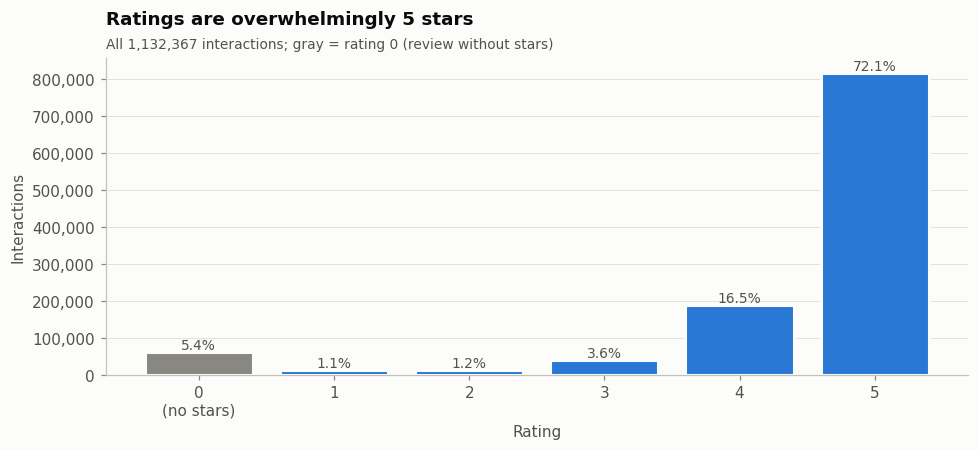

In [4]:
counts = inter["rating"].value_counts().sort_index()
fig, ax = plt.subplots()
colors = [MUTED if r == 0 else BLUE for r in counts.index]
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor=SURFACE, linewidth=2, width=0.8)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v / counts.sum():.1%}", ha="center", va="bottom",
            color=TEXT2, fontsize=9)
ax.set_xticks(counts.index, ["0\n(no stars)", "1", "2", "3", "4", "5"])
thousands(ax)
finish(ax, "Ratings are overwhelmingly 5 stars", "Rating", "Interactions",
       subtitle=f"All {counts.sum():,} interactions; gray = rating 0 (review without stars)")

### 1.2 Distribution of average ratings per user

All users: mean 4.56, share exactly 5.0 = 66.2%
≥5 ratings: mean 4.65, share exactly 5.0 = 21.8%


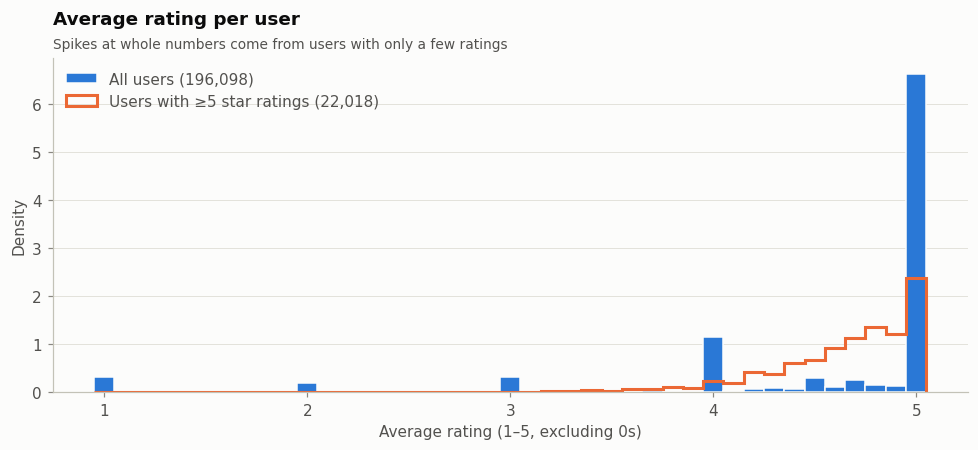

In [5]:
ax = avg_rating_hist(user_stats, "user")
finish(ax, "Average rating per user", "Average rating (1–5, excluding 0s)", "Density",
       subtitle="Spikes at whole numbers come from users with only a few ratings")

### 1.3 Distribution of average ratings per recipe

All recipes: mean 4.58, share exactly 5.0 = 48.6%
≥5 ratings: mean 4.69, share exactly 5.0 = 20.8%


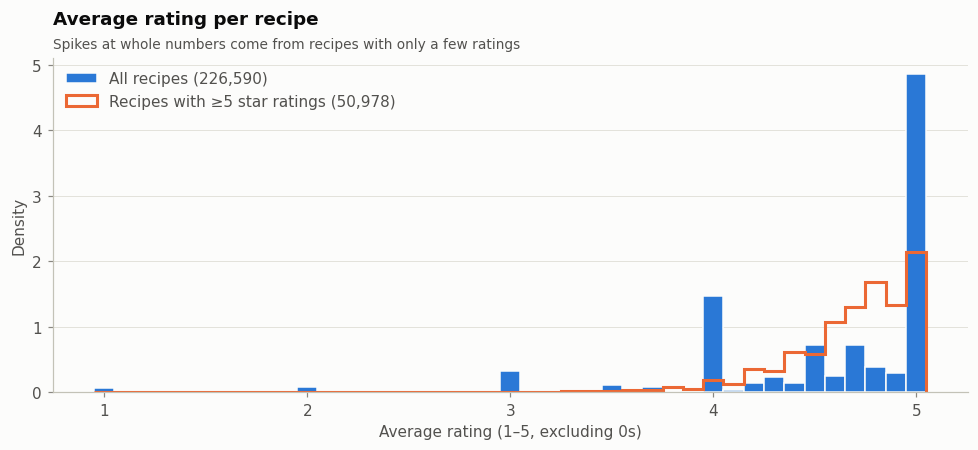

In [6]:
ax = avg_rating_hist(recipe_stats, "recipe")
finish(ax, "Average rating per recipe", "Average rating (1–5, excluding 0s)", "Density",
       subtitle="Spikes at whole numbers come from recipes with only a few ratings")

## Section 2 — Understanding user behavior

### 2.1 Distribution of number of reviews per user

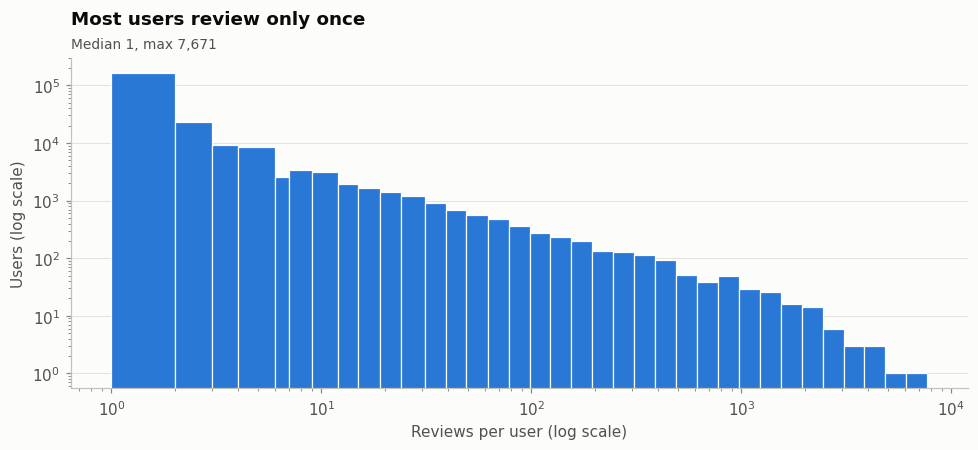

,users kept,% of users,% of interactions kept
min reviews per user,,,
1,"226,570",100.0%,100.0%
2,"60,314",26.6%,85.3%
3,"37,576",16.6%,81.3%
5,"23,086",10.2%,77.0%
10,"12,486",5.5%,70.9%
20,"6,687",3.0%,64.1%
50,"2,755",1.2%,53.6%


In [7]:
ax = count_hist(user_stats["n_reviews"], "user")
finish(ax, "Most users review only once", "Reviews per user (log scale)", "Users (log scale)",
       subtitle=f"Median {user_stats.n_reviews.median():.0f}, max {user_stats.n_reviews.max():,}")
threshold_table(user_stats["n_reviews"], "user")

### 2.2 Number of reviews per user vs. average rating

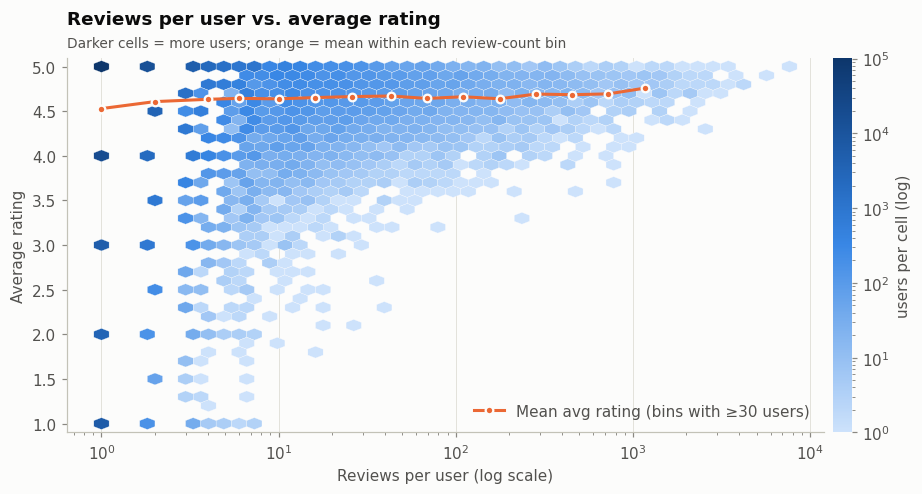

In [8]:
ax, g = count_vs_rating(user_stats, "user")
finish(ax, "Reviews per user vs. average rating", "Reviews per user (log scale)", "Average rating",
       subtitle="Darker cells = more users; orange = mean within each review-count bin")

## Section 3 — Understanding recipe characteristics

### 3.1 Distribution of number of ingredients

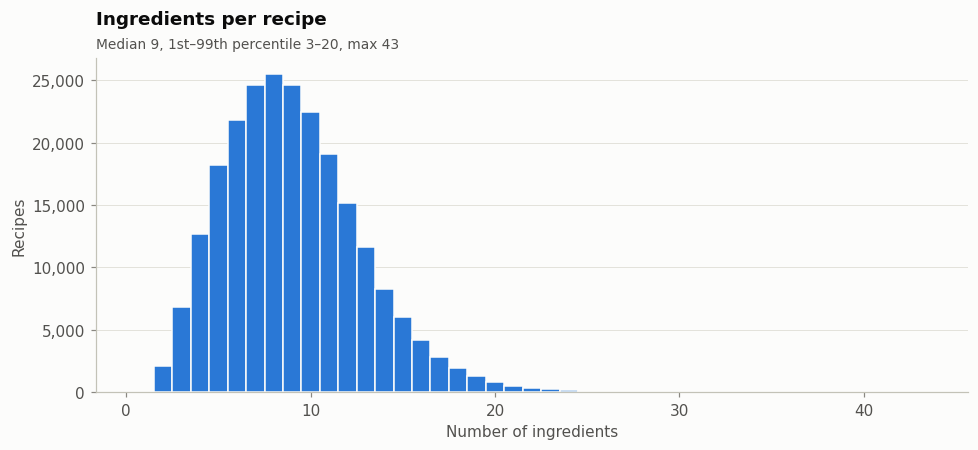

In [9]:
vc = recipes["n_ingredients"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(vc.index, vc.values, color=BLUE, edgecolor=SURFACE, linewidth=1, width=1)
thousands(ax)
s = recipes["n_ingredients"]
finish(ax, "Ingredients per recipe", "Number of ingredients", "Recipes",
       subtitle=f"Median {s.median():.0f}, 1st–99th percentile {s.quantile(.01):.0f}–{s.quantile(.99):.0f}, max {s.max()}")

### 3.2 Distribution of number of cooking steps

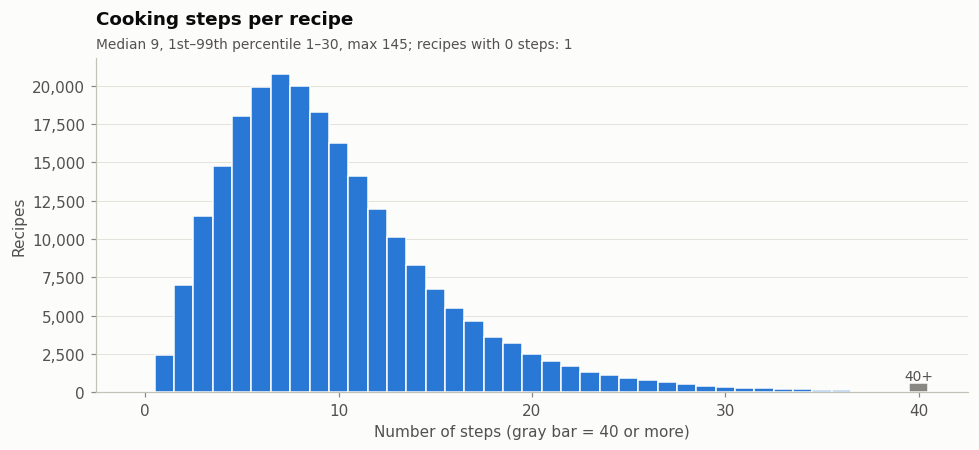

In [10]:
CAP = 40
s = recipes["n_steps"]
vc = s.clip(upper=CAP).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(vc.index, vc.values, color=[BLUE] * (len(vc) - 1) + [MUTED], edgecolor=SURFACE, linewidth=1, width=1)
ax.text(CAP, vc.iloc[-1], f"{CAP}+", ha="center", va="bottom", color=TEXT2, fontsize=9)
thousands(ax)
finish(ax, "Cooking steps per recipe", f"Number of steps (gray bar = {CAP} or more)", "Recipes",
       subtitle=f"Median {s.median():.0f}, 1st–99th percentile {s.quantile(.01):.0f}–{s.quantile(.99):.0f}, "
                f"max {s.max()}; recipes with 0 steps: {(s == 0).sum()}")

### 3.3 Distribution of reviews per recipe

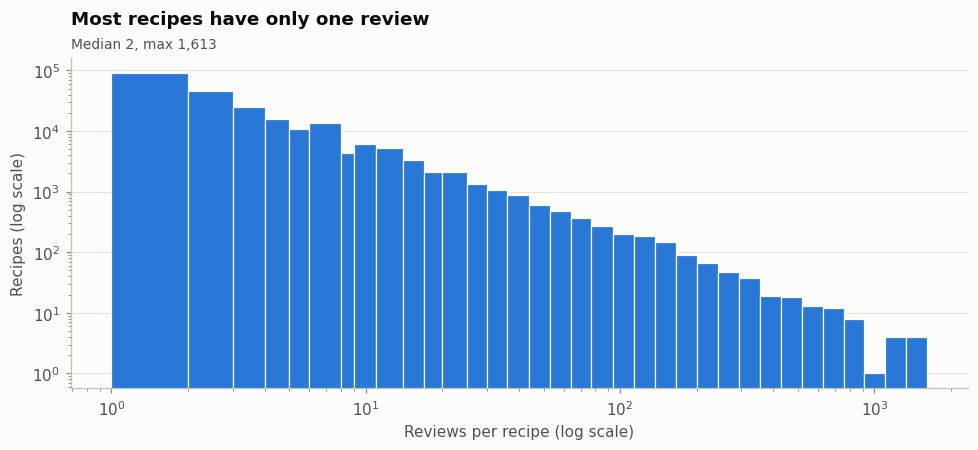

,recipes kept,% of recipes,% of interactions kept
min reviews per recipe,,,
1,"231,637",100.0%,100.0%
2,"139,684",60.3%,91.9%
3,"94,564",40.8%,83.9%
5,"53,593",23.1%,71.7%
10,"21,399",9.2%,53.4%
20,"7,982",3.4%,37.7%
50,"2,164",0.9%,22.7%


In [11]:
ax = count_hist(recipe_stats["n_reviews"], "recipe")
finish(ax, "Most recipes have only one review", "Reviews per recipe (log scale)", "Recipes (log scale)",
       subtitle=f"Median {recipe_stats.n_reviews.median():.0f}, max {recipe_stats.n_reviews.max():,}")
threshold_table(recipe_stats["n_reviews"], "recipe")

## Section 4 — Exploring relationships

### 4.1 Number of reviews per recipe vs. average rating

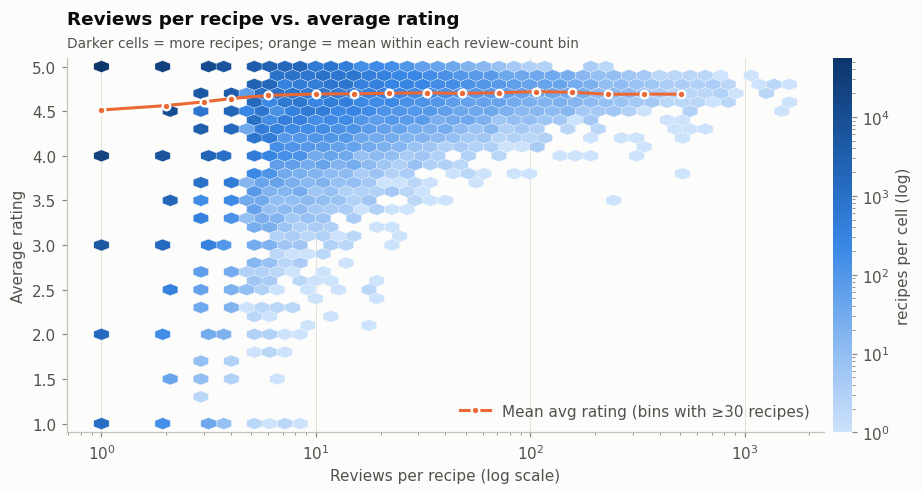

In [12]:
ax, g = count_vs_rating(recipe_stats, "recipe")
finish(ax, "Reviews per recipe vs. average rating", "Reviews per recipe (log scale)", "Average rating",
       subtitle="Darker cells = more recipes; orange = mean within each review-count bin")

### 4.2 Number of ingredients vs. average rating

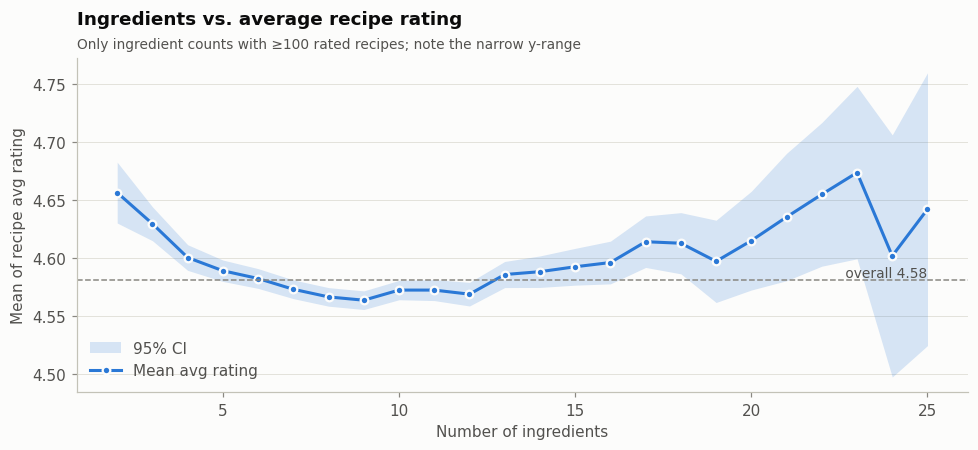

In [13]:
ax, g = feature_vs_rating("n_ingredients", "ingredients")
finish(ax, "Ingredients vs. average recipe rating", "Number of ingredients", "Mean of recipe avg rating",
       subtitle="Only ingredient counts with ≥100 rated recipes; note the narrow y-range")

### 4.3 Number of steps vs. average rating

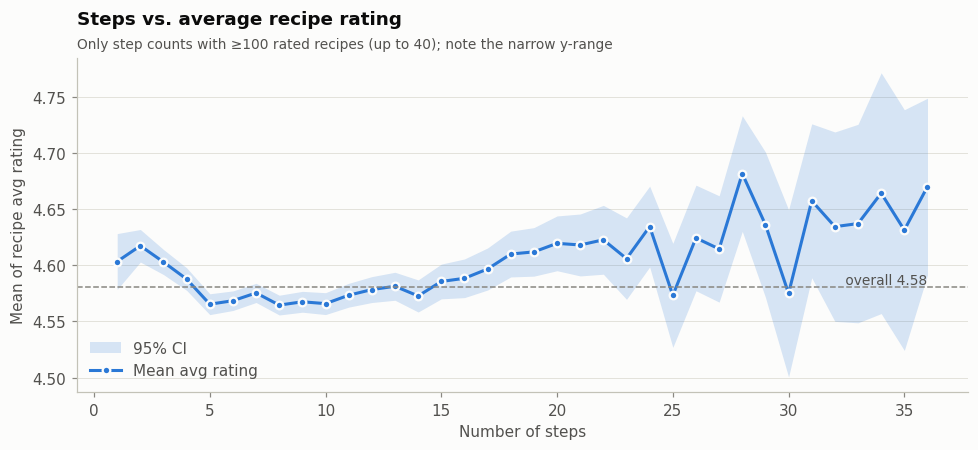

In [14]:
ax, g = feature_vs_rating("n_steps", "steps", max_val=40)
finish(ax, "Steps vs. average recipe rating", "Number of steps", "Mean of recipe avg rating",
       subtitle="Only step counts with ≥100 rated recipes (up to 40); note the narrow y-range")

### 4.4 Rating distributions across recipe popularity groups

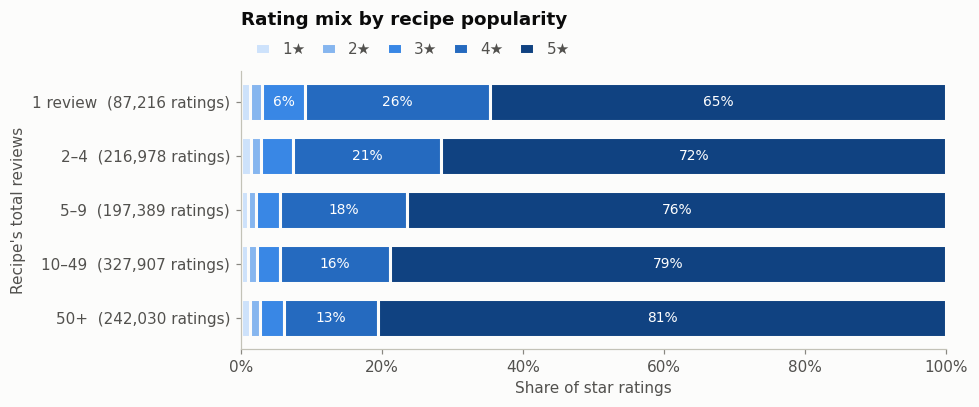

rating,1,2,3,4,5
group,,,,,
1 review,1.3%,1.7%,6.1%,26.2%,64.7%
2–4,1.4%,1.4%,4.6%,21.0%,71.6%
5–9,1.0%,1.1%,3.5%,18.0%,76.4%
10–49,1.1%,1.2%,3.2%,15.6%,78.9%
50+,1.3%,1.4%,3.4%,13.3%,80.6%


In [15]:
edges = [1, 2, 5, 10, 50, np.inf]
labels = ["1 review", "2–4", "5–9", "10–49", "50+"]
pop = pd.cut(recipe_stats["n_reviews"], edges, right=False, labels=labels)
r = rated[["recipe_id", "rating"]].assign(group=rated["recipe_id"].map(pop))
share = pd.crosstab(r["group"], r["rating"], normalize="index").reindex(labels)
n_per = r["group"].value_counts().reindex(labels)

steps = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"]   # 1★ light -> 5★ dark
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(share))
for star, color in zip(share.columns, steps):
    vals = share[star].values
    ax.barh(range(len(share)), vals, left=left, color=color, edgecolor=SURFACE, linewidth=2, height=0.7,
            label=f"{star}★")
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.06:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if star >= 3 else TEXT)
    left += vals
ax.set_yticks(range(len(share)), [f"{g}  ({n:,} ratings)" for g, n in zip(labels, n_per)])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1, columnspacing=1)
ax.set_title("Rating mix by recipe popularity", pad=30)
ax.set_xlabel("Share of star ratings"); ax.set_ylabel("Recipe's total reviews")
plt.tight_layout(); plt.show()
share.style.format("{:.1%}")